Note: Run locally so ../../data/ resolves correctly from the project root.

# <a id='toc1_'></a>[Title](#toc0_)
- Ramon Casas i Luque
- Marina Velasco Barriuso
- Shaoya Zhang

**Table of contents**<a id='toc0_'></a>    
  - [Import libraries and data](#toc1_1_)    
  - [Check NaNs, cast data types](#toc1_2_)    
  - [Part 1: Preprocessing the documents](#toc1_3_)    
  - [Part 2: EDA](#toc1_4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[Import libraries and data](#toc0_)

In [7]:
import pandas as pd
import seaborn as sns
from nltk.stem import PorterStemmer
from nltk.tokenize import RegexpTokenizer
from nltk.corpus import stopwords
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/mvelasco/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [8]:
# Read fashion products dataset
data_dir = "../../data/"
filename = "fashion_products_dataset.json"
df = pd.read_json(data_dir+filename)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28080 entries, 0 to 28079
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   _id              28080 non-null  object        
 1   actual_price     28080 non-null  object        
 2   average_rating   28080 non-null  object        
 3   brand            28080 non-null  object        
 4   category         28080 non-null  object        
 5   crawled_at       28080 non-null  datetime64[ns]
 6   description      28080 non-null  object        
 7   discount         28080 non-null  object        
 8   images           28080 non-null  object        
 9   out_of_stock     28080 non-null  bool          
 10  pid              28080 non-null  object        
 11  product_details  28080 non-null  object        
 12  seller           28080 non-null  object        
 13  selling_price    28080 non-null  object        
 14  sub_category     28080 non-null  objec

## <a id='toc1_2_'></a>[Check NaNs, cast data types](#toc0_)

Missing values, including empty and whitespace-only strings:


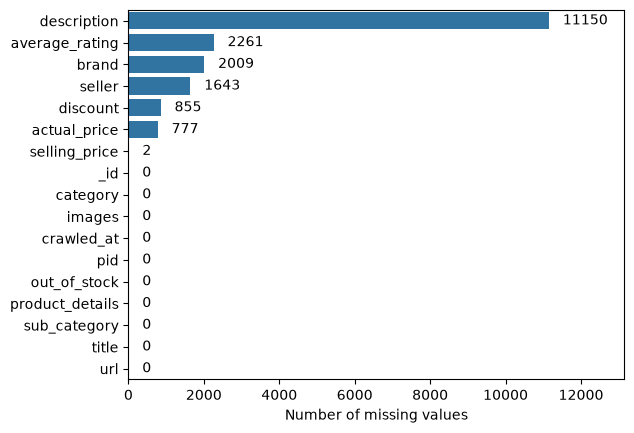

In [9]:
# Verify product identifiers are unique
assert df["pid"].notna().all()
assert df["pid"].is_unique

# Check for missing values, including empty and whitespace-only strings
print("Missing values, including empty and whitespace-only strings:")
missing = df.replace(r"^\s*$", pd.NA, regex=True).isna().sum()

# Horizontal barplot
ax = sns.barplot(missing.sort_values(ascending=False), orient='h')
ax.set_xlabel("Number of missing values")
ax.set_xlim(right=max(missing)+2000)
for container in ax.containers:
    ax.bar_label(container, padding=10)

Before proceeding, we convert all numeric columns from strings to float. The column `out_of_stock` is already boolean, so we keep it unchanged.

In [10]:
df_old = df.copy()

# Convert prices to numeric values:
# "2,999" -> 2999; missing or invalid values -> NaN
for column in ["actual_price", "selling_price"]:
    cleaned = (
        df_old[column]
        .astype("string")
        .str.replace(",", "", regex=False)
        .str.strip()
    )

    df[column] = pd.to_numeric(cleaned, errors="raise")

# Convert discounts to percentage points:
# "69% off" -> 0.69; missing or invalid values -> NaN
df["discount"] = pd.to_numeric(
    df_old["discount"]
    .astype("string")
    .str.extract(r"^\s*(\d+(?:\.\d+)?)\s*%\s*off\s*$", expand=False)
)/100

# Convert ratings to numeric values:
# "3.9" -> 3.9; missing or invalid values -> NaN
df["average_rating"] = pd.to_numeric(
    df_old["average_rating"].astype("string").str.strip(),
    errors="coerce"
)

# Show the dataframe with the new numeric columns
numeric_cols = ["actual_price", "selling_price", "discount", "average_rating"]
print("Before:")
display(df_old[numeric_cols].head(3))
print("After:")
display(df[numeric_cols].head(3))

# Verify new data types are Float64
print("Data types of numeric fields:")
display(df[numeric_cols].dtypes)

Before:


,actual_price,selling_price,discount,average_rating
0,"2,999",921,69% off,3.9
1,"1,499",499,66% off,3.9
2,"2,999",931,68% off,3.9


After:


,actual_price,selling_price,discount,average_rating
0,2999.0,921.0,0.69,3.9
1,1499.0,499.0,0.66,3.9
2,2999.0,931.0,0.68,3.9


Data types of numeric fields:


actual_price      Float64
selling_price     Float64
discount          Float64
average_rating    Float64
dtype: object

## <a id='toc1_3_'></a>[Part 1: Preprocessing the documents](#toc0_)

In this part we create two dataframes:

1. `df` has product information *without* preprocessing. For example, in the first row ‘description’ = ‘Wool Black pants made out of 100% cotton’.
2. `index_df` only contains the fields we’ll use in the index. All fields are pre-processed (lowercase, stemmed, etc.). For example, in the first row ‘description’ = [‘wool', 'black', 'pant', 'mad', '100', 'cotton’].

The first dataframe holds the information we'll later display in the search results: the product's title, description, etc. as it was originally written. The second will be used to create the index and to perform the exploratory data analysis (EDA). We are interested in keeping the fields separate in both cases so we give each field a different weight in the index.

In [ ]:
# Preprocess the text of the description column
def build_terms(text):
    """
    Preprocess text removing stop words, stemming,
    transforming in lowercase and return the tokens of the text.

    :param text: to be preprocessed
    :returns: a list of tokens corresponding to the input text after the preprocessing
    """

    stemmer = PorterStemmer()
    tokenizer = RegexpTokenizer(r'\w+')             # keep only words & numbers, drop punctuation
    stop_words = set(stopwords.words("english"))
    for w in ['not', 'no']:
        stop_words.remove(w)                        # keep 'no' and 'not' to preserve meaning of sentences like "shirt with no sleeves"
    text= text.lower()                              # transform in lowercase
    text=  tokenizer.tokenize(text)                 # tokenize the text to get a list of terms
    text=[t for t in text if t not in stop_words]   # eliminate the stopwords
    text=[stemmer.stem(t) for t in text]            # perform stemming
    return text

test_row = df.iloc[0]
print(f"Before: {test_row['description']}") 
print(f"After: {build_terms(test_row['description'])}")

Before: Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India
After: ['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friendli', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudli', 'made', 'india']


In [12]:
index_df = pd.DataFrame()
index_df['pid'] = df['pid']

index_cols = ["title", "description", "brand", "category", "sub_category", "seller"]
for col in index_cols:
    index_df[col] = df[col].apply(build_terms)
index_df.head(3)

,pid,title,description,brand,category,sub_category,seller
0,TKPFCZ9EA7H5FYZH,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]"
1,TKPFCZ9EJZV2UVRZ,"[solid, men, blue, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]"
2,TKPFCZ9EHFCY5Z4Y,"[solid, men, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]"


The column `product_details` also includes some information that might be useful for the index. The problem is it is structured as a dictionary. Also, we don't want to include the dictionary keys, they'd simply add noise to our terms.

In [13]:
test_row.product_details

[{'Style Code': '1005COMBO2'},
 {'Closure': 'Elastic'},
 {'Pockets': 'Side Pockets'},
 {'Fabric': 'Cotton Blend'},
 {'Pattern': 'Solid'},
 {'Color': 'Multicolor'}]

Therefore, we get the values of the dictionary, extract the terms and add them to our `index_df`.

In [14]:
def values_to_string(details):
    """
    Convert a product's details into a single string of its values.

    :param details: list of single-entry dicts, e.g. [{'Closure': 'Elastic'}, {'Color': 'Multicolor'}]
    :returns: a string with all the detail values joined by spaces (e.g. 'Elastic Multicolor'),
              or NaN if the input is not a list
    """
    if not isinstance(details, list):
        return pd.NA
    return " ".join(str(v) for d in details for v in d.values())

In [15]:
# Preprocess (lowercase, stem, etc.) and add to our index info 
index_df['product_details'] = df['product_details'].apply(values_to_string).apply(build_terms)
index_df.head(5)

,pid,title,description,brand,category,sub_category,seller,product_details
0,TKPFCZ9EA7H5FYZH,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]","[1005combo2, elast, side, pocket, cotton, blen..."
1,TKPFCZ9EJZV2UVRZ,"[solid, men, blue, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]","[1005blue, drawstr, elast, side, pocket, cotto..."
2,TKPFCZ9EHFCY5Z4Y,"[solid, men, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]","[1005combo4, elast, side, pocket, cotton, blen..."
3,TKPFCZ9ESZZ7YWEF,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]","[1005combo3, elast, side, pocket, cotton, blen..."
4,TKPFCZ9EVXKBSUD7,"[solid, women, brown, grey, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]","[1005combo1, drawstr, elast, side, pocket, cot..."


In [16]:
df.to_csv(data_dir + f"fashion_products.csv", index=False)
index_df.to_csv(data_dir + f"index_info.csv", index=False)
print(f"✅ Saved 2 files to {data_dir}")

✅ Saved 2 files to ../../data/


In [17]:
df.head()

,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,2999.0,3.9,York,Clothing and Accessories,2021-02-10 20:11:51,Yorker trackpants made from 100% rich combed c...,0.69,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921.0,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,893e6980-f2a0-531f-b056-34dd63fe912c,1499.0,3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed c...,0.66,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499.0,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,2999.0,3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed c...,0.68,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931.0,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
3,3f3f97bb-5faf-57df-a9ff-1af24e2b1045,2999.0,3.9,York,Clothing and Accessories,2021-02-10 20:11:53,Yorker trackpants made from 100% rich combed c...,0.69,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9ESZZ7YWEF,"[{'Style Code': '1005COMBO3'}, {'Closure': 'El...",Shyam Enterprises,911.0,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
4,750caa3d-6264-53ca-8ce1-94118a1d8951,2999.0,3.9,York,Clothing and Accessories,2021-02-10 20:11:53,Yorker trackpants made from 100% rich combed c...,0.68,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EVXKBSUD7,"[{'Style Code': '1005COMBO1'}, {'Closure': 'Dr...",Shyam Enterprises,943.0,Bottomwear,"Solid Women Brown, Grey Track Pants",https://www.flipkart.com/yorker-solid-men-brow...


## <a id='toc1_4_'></a>[Part 2: EDA](#toc0_)

In this part we conduct Exploratory Data Analysis in order to know better the data we are working with. We split this analysis in the following parts:


1. [Category distribution](#Category-distribution)
2. [Price distributions](#Price-distributions)
3. [Rating and discount distributions](#Rating-and-discount-distributions)
4. [Top brands and sellers by product quantity](#Top-brands-and-sellers-by-product-quantity)
5. [Stock availability](#Stock-availability)
6. [Length distributions](#Length-distributions)
7. [Most Common Words](#Most-Common-Words)
8. [Name Entity Recognition](#Name-Entity-Recognition)

### Category distribution

Count products using the original category names in `df`. The first plot compares all categories; the next two show the most and least frequent subcategories. These plots describe the dataset composition without changing it.


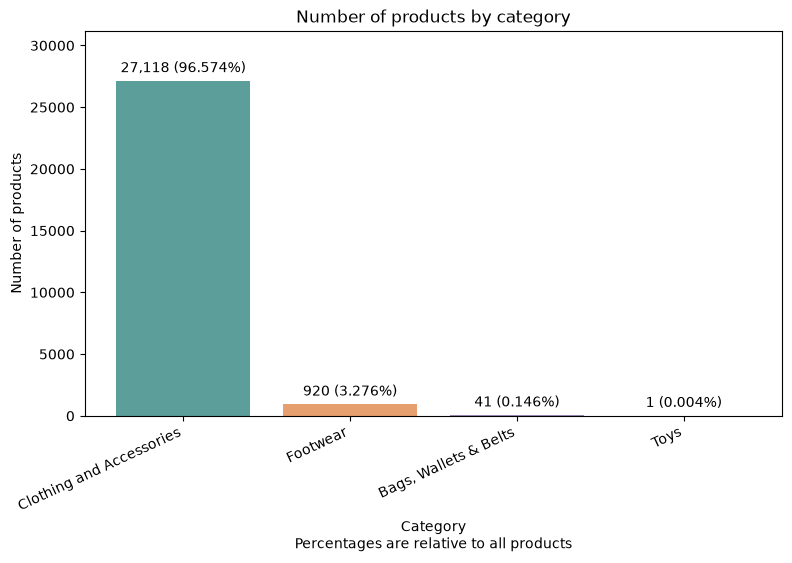

In [18]:
import matplotlib.pyplot as plt

# Each row is one product because pid is unique.
category_counts = df["category"].value_counts()

plt.figure(figsize=(9, 5))
bars = plt.bar(category_counts.index, category_counts.values,
               color=["#5B9E9A", "#E6A06F", "#9B8CB9", "#D7BA65"])
plt.bar_label(
    bars,
    labels=[f"{n:,} ({n / len(df):.3%})" for n in category_counts.values],
    padding=4
)
plt.ylim(0, category_counts.max() * 1.15)
plt.title("Number of products by category")
plt.xlabel("Category\nPercentages are relative to all products")
plt.ylabel("Number of products")
plt.xticks(rotation=25, ha="right")
# plt.tight_layout()
plt.show()


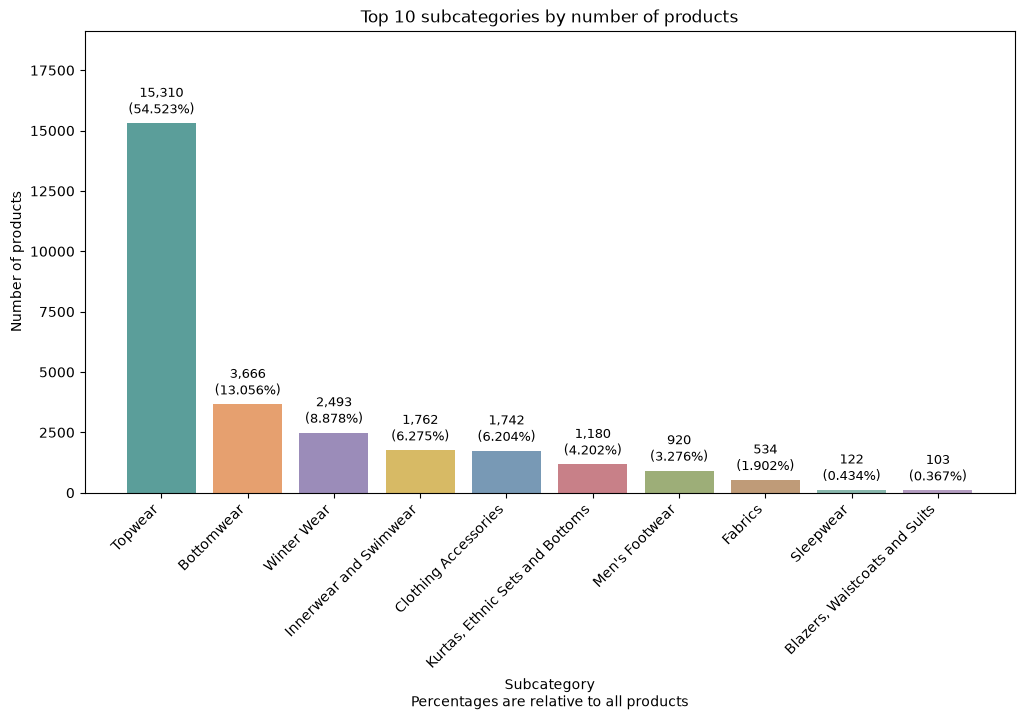

In [19]:
subcategory_counts = df["sub_category"].value_counts()
top_subcategories = subcategory_counts.head(10)

plt.figure(figsize=(12, 6))
subcategory_palette = ["#5B9E9A", "#E6A06F", "#9B8CB9", "#D7BA65",
                       "#7899B5", "#C88088", "#9DAE78", "#BF9B78",
                       "#89B8AD", "#B49DC1"]
subcategory_colors = {name: subcategory_palette[i % len(subcategory_palette)]
                      for i, name in enumerate(subcategory_counts.index)}
bars = plt.bar(top_subcategories.index, top_subcategories.values,
        color=[subcategory_colors[name] for name in top_subcategories.index])
plt.bar_label(
    bars,
    labels=[f"{n:,}\n({n / len(df):.3%})" for n in top_subcategories.values],
    padding=4,
    fontsize=9
)
plt.ylim(0, top_subcategories.max() * 1.25)
plt.title("Top 10 subcategories by number of products")
plt.xlabel("Subcategory\nPercentages are relative to all products")
plt.ylabel("Number of products")
plt.xticks(rotation=45, ha="right")
# plt.tight_layout()
plt.show()


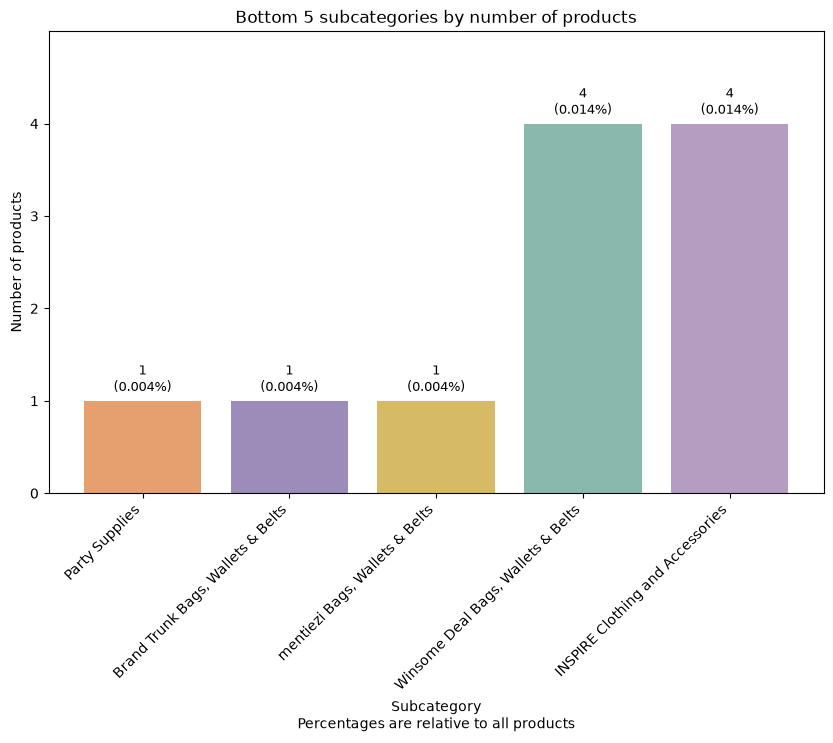

In [20]:
# Select five of the least frequent subcategories; counts may be tied.
bottom_subcategories = subcategory_counts.nsmallest(5)

plt.figure(figsize=(10, 6))
bars = plt.bar(bottom_subcategories.index, bottom_subcategories.values,
        color=[subcategory_colors[name] for name in bottom_subcategories.index])
plt.bar_label(
    bars,
    labels=[f"{n:,}\n({n / len(df):.3%})" for n in bottom_subcategories.values],
    padding=4,
    fontsize=9
)
plt.ylim(0, bottom_subcategories.max() * 1.25)
plt.title("Bottom 5 subcategories by number of products")
plt.xlabel("Subcategory\nPercentages are relative to all products")
plt.ylabel("Number of products")
plt.yticks(range(int(bottom_subcategories.max()) + 1))
plt.xticks(rotation=45, ha="right")
# plt.tight_layout()
plt.show()


Compare the dominant category with the others, then inspect the concentration in the largest subcategories. The Bottom 5 plot shows five of the smallest groups; ties mean that other groups can have the same counts.


### Price distributions

Use the cleaned numeric prices in `df`. Exclude missing values separately for
each price field, retaining the other product records. Titles show valid sample
sizes and medians. Both panels use the same price range for comparison; no
currency is assumed because its unit has not been verified.


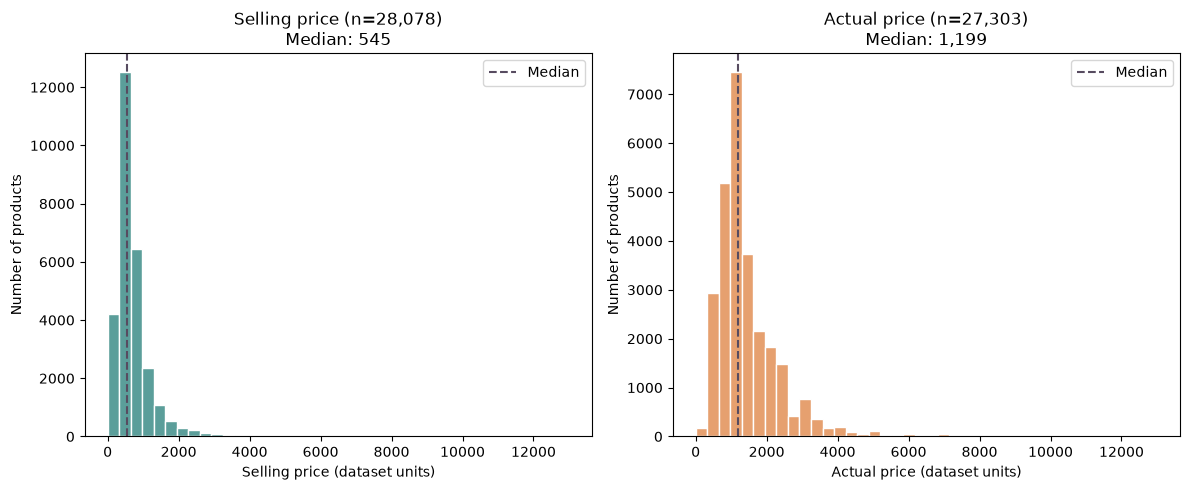

In [21]:
selling_prices = df["selling_price"].dropna()
actual_prices = df["actual_price"].dropna()
price_limit = max(selling_prices.max(), actual_prices.max())

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(selling_prices.astype(float), bins=40, range=(0, price_limit), color="#5B9E9A", edgecolor="white")
plt.axvline(selling_prices.median(), color="#574B60", linestyle="--", label="Median")
plt.title(f"Selling price (n={len(selling_prices):,})\nMedian: {selling_prices.median():,.0f}")
plt.xlabel("Selling price (dataset units)")
plt.ylabel("Number of products")
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(actual_prices.astype(float), bins=40, range=(0, price_limit), color="#E6A06F", edgecolor="white")
plt.axvline(actual_prices.median(), color="#574B60", linestyle="--", label="Median")
plt.title(f"Actual price (n={len(actual_prices):,})\nMedian: {actual_prices.median():,.0f}")
plt.xlabel("Actual price (dataset units)")
plt.ylabel("Number of products")
plt.legend()
plt.tight_layout()
plt.show()


### Rating and discount distributions

Missing ratings and discounts are excluded separately, not filled with zero or
the mean. The cleaned discount is a proportion, so multiply by 100 for plotting
percentage values. All valid values are retained.


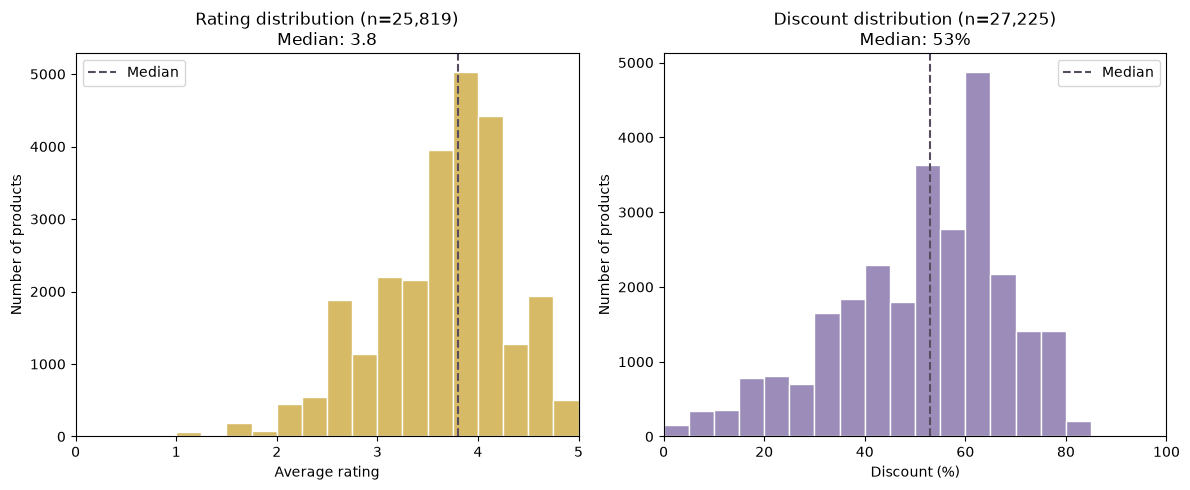

In [22]:
ratings = df["average_rating"].dropna()
discounts = df["discount"].dropna() * 100

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(ratings.astype(float), bins=20, range=(0, 5), color="#D7BA65", edgecolor="white")
plt.axvline(ratings.median(), color="#574B60", linestyle="--", label="Median")
plt.title(f"Rating distribution (n={len(ratings):,})\nMedian: {ratings.median():.1f}")
plt.xlabel("Average rating")
plt.ylabel("Number of products")
plt.xlim(0, 5)
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(discounts.astype(float), bins=20, range=(0, 100), color="#9B8CB9", edgecolor="white")
plt.axvline(discounts.median(), color="#574B60", linestyle="--", label="Median")
plt.title(f"Discount distribution (n={len(discounts):,})\nMedian: {discounts.median():.0f}%")
plt.xlabel("Discount (%)")
plt.ylabel("Number of products")
plt.xlim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()


### Top brands and sellers by product quantity

Count product records, not sales. Exclude missing or blank names, trim whitespace,
and group case-insensitively while preserving a readable name for display.
These temporary Series do not change the original names in `df`.


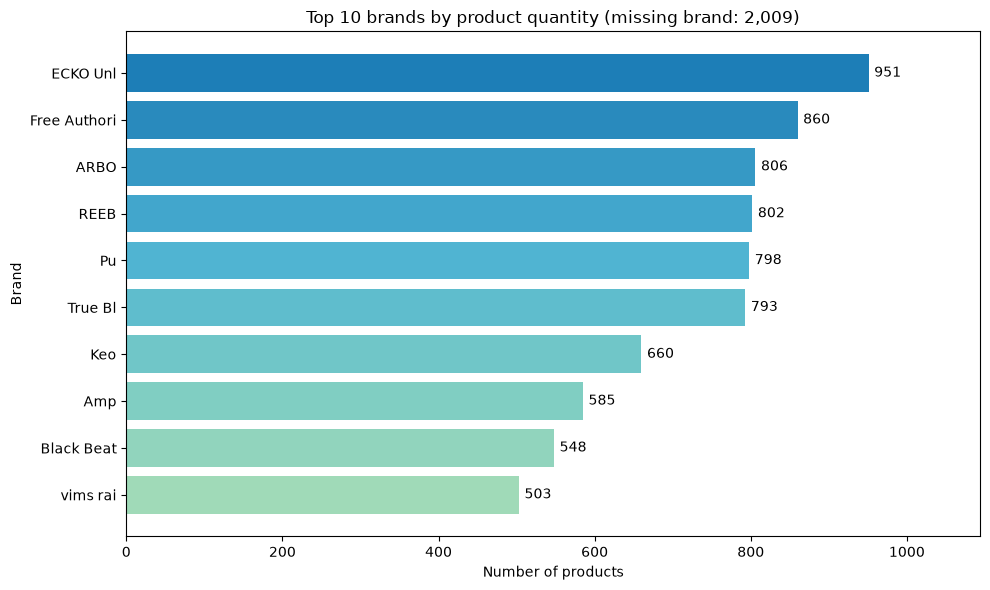

In [23]:
brand_names = df["brand"].astype("string").str.strip().replace("", pd.NA)
brand_keys = brand_names.str.casefold()
brand_counts = brand_keys.value_counts().head(10)
brand_labels = brand_names.groupby(brand_keys).first().reindex(brand_counts.index)

plt.figure(figsize=(10, 6))
bars = plt.barh(brand_labels, brand_counts.values,
                color=plt.cm.GnBu([0.8 - i * 0.045 for i in range(len(brand_counts))]))
plt.gca().invert_yaxis()
plt.bar_label(bars, padding=4)
plt.xlim(0, brand_counts.max() * 1.15)
plt.title(f"Top 10 brands by product quantity (missing brand: {brand_names.isna().sum():,})")
plt.xlabel("Number of products")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()


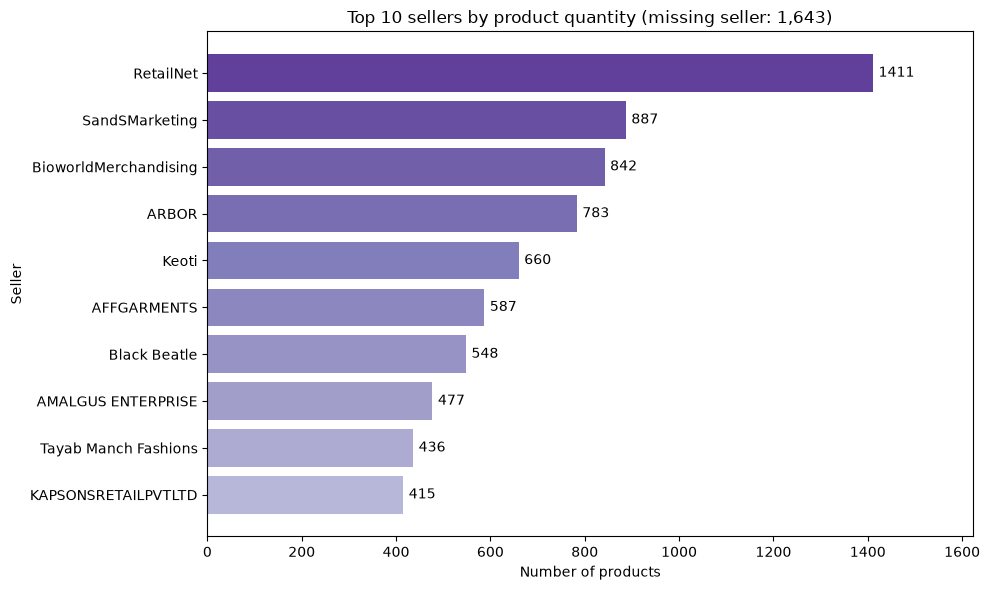

In [24]:
seller_names = df["seller"].astype("string").str.strip().replace("", pd.NA)
seller_keys = seller_names.str.casefold()
seller_counts = seller_keys.value_counts().head(10)
seller_labels = seller_names.groupby(seller_keys).first().reindex(seller_counts.index)

plt.figure(figsize=(10, 6))
bars = plt.barh(seller_labels, seller_counts.values,
                color=plt.cm.Purples([0.8 - i * 0.045 for i in range(len(seller_counts))]))
plt.gca().invert_yaxis()
plt.bar_label(bars, padding=4)
plt.xlim(0, seller_counts.max() * 1.15)
plt.title(f"Top 10 sellers by product quantity (missing seller: {seller_names.isna().sum():,})")
plt.xlabel("Number of products")
plt.ylabel("Seller")
plt.tight_layout()
plt.show()


### Stock availability

`out_of_stock=False` means in stock; `True` means out of stock. Percentages use
products with a known stock status. This describes availability at collection
time, not changes in stock over time.


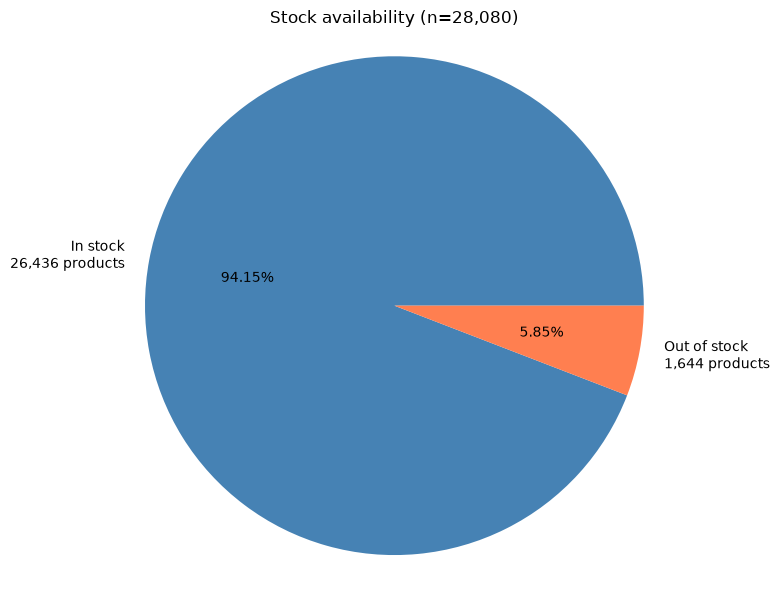

In [25]:
stock = df["out_of_stock"].dropna()
stock_counts = [stock.eq(False).sum(), stock.eq(True).sum()]

plt.figure(figsize=(7, 6))
plt.pie(
    stock_counts,
    labels=[f"In stock\n{stock_counts[0]:,} products",
            f"Out of stock\n{stock_counts[1]:,} products"],
    autopct="%1.2f%%",
    startangle=0,
    colors=["steelblue", "coral"]
)
plt.title(f"Stock availability (n={len(stock):,})")
plt.axis("equal")
plt.tight_layout()
plt.show()


### Length distributions

,count,mean,std,min,25%,50%,75%,95%,99%,max
title,28080.0,6.27,1.99,1.0,5.0,6.0,7.0,9.0,12.0,31.0
description,28080.0,18.92,26.85,0.0,0.0,9.0,29.0,75.0,108.0,579.0
final_tokens,28080.0,56.47,32.92,10.0,34.0,46.0,70.0,125.0,165.0,627.0


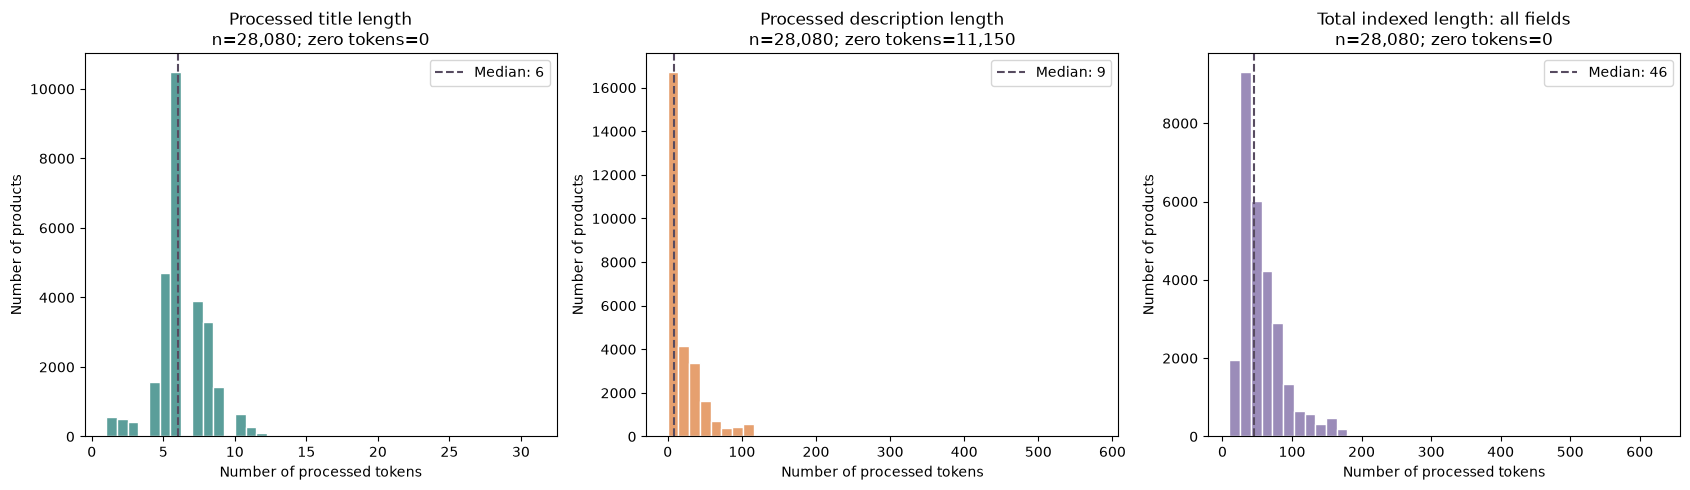

In [26]:
# same index_cols from preprocessing; product_details was added afterward
eda_index_fields = [*index_cols, "product_details"]

# count of existing tokens once per field and product
token_lengths = index_df[eda_index_fields].apply(lambda column: column.map(len))
text_lengths = token_lengths[["title", "description"]].copy()
text_lengths["final_tokens"] = token_lengths.sum(axis=1)

display(
    text_lengths.describe(
        percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]
    ).round(2).T
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

length_panels = [
    ("title", "Processed title length", "#5B9E9A"),
    ("description", "Processed description length", "#E6A06F"),
    ("final_tokens", "Total indexed length: all fields", "#9B8CB9")
]

for ax, (column, title, color) in zip(axes, length_panels):
    values = text_lengths[column]

    ax.hist(values, bins=40, color=color, edgecolor="white")
    ax.axvline(
        values.median(),
        color="#574B60",
        linestyle="--",
        label=f"Median: {values.median():.0f}"
    )

    ax.set_title(
        f"{title}\n"
        f"n={len(values):,}; zero tokens={values.eq(0).sum():,}"
    )
    ax.set_xlabel("Number of processed tokens")
    ax.set_ylabel("Number of products")
    ax.legend()

plt.tight_layout()
plt.show()


We can observe that titles are mostly short and with a consistent length overall. The median length is 6 processed tokens per tiles, while 95% of them contain at most 9 tokens.

In constrast, descriptions vary much more and some are even 579 tokens long. However, 11,150 products, representing 39.7%, have no description. It follows from this that descriptions provide a limited coverage of our product catalogue: titles and other indexed fields will be still important to represent this products.

Taking into account the total indexed length, i.e. all indexed fields, the median is in 45 tokens. Observing this variation in text length will make us consider length normalization when we design a retrieval stage.

### Most Common Terms

In [27]:
from collections import Counter
from math import ceil

Top 20 processed terms in title:


,term,corpus_count,document_count,products_pct
0,shirt,15838,15838,56.40
1,women,13146,13041,46.44
2,men,13060,13021,46.37
3,neck,11952,11952,42.56
4,solid,9246,9215,32.82
5,round,8301,8301,29.56
6,print,8123,8106,28.87
7,pack,4839,4787,17.05
8,blue,4378,4282,15.25
9,fit,3923,3923,13.97


Top 20 processed terms in description:


,term,corpus_count,document_count,products_pct
0,shirt,18180,8362,29.78
1,cotton,10139,7248,25.81
2,wear,9353,5416,19.29
3,comfort,8836,6796,24.20
4,look,6413,4398,15.66
5,casual,6034,4824,17.18
6,fit,5831,4602,16.39
7,made,5619,4399,15.67
8,fabric,5516,4340,15.46
9,print,4888,3294,11.73


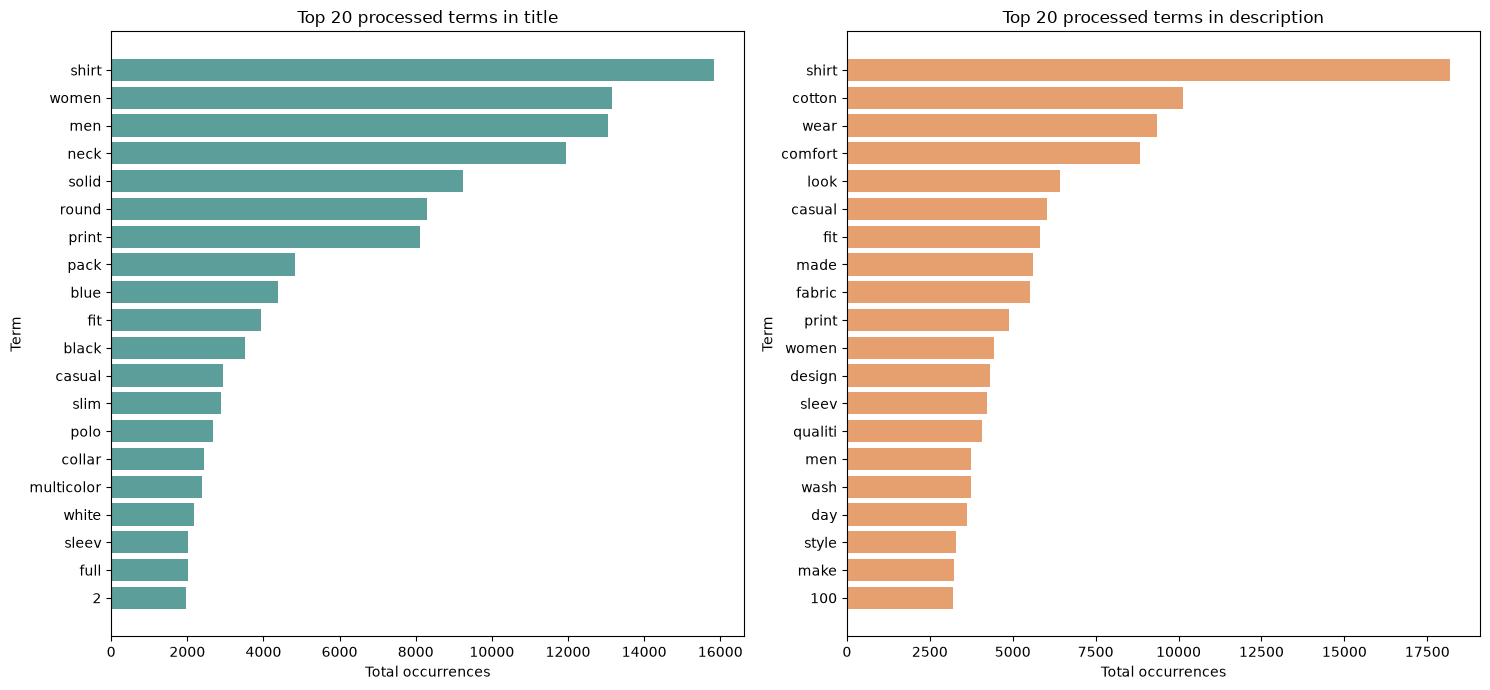

In [28]:
term_counts = {}
term_tables = {}

for field in ["title", "description"]:
    occurrence_counts = Counter()
    document_counts = Counter()

    for tokens in index_df[field]:
        occurrence_counts.update(tokens)
        document_counts.update(set(tokens))

    term_counts[field] = occurrence_counts

    table = pd.DataFrame(
        occurrence_counts.most_common(),
        columns=["term", "corpus_count"]
    )

    table["document_count"] = (
        table["term"].map(document_counts).astype(int)
    )
    table["products_pct"] = (
        100 * table["document_count"] / len(index_df)
    ).round(2)

    term_tables[field] = table

    print(f"Top 20 processed terms in {field}:")
    display(table.head(20))

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, field, color in zip(
    axes,
    ["title", "description"],
    ["#5B9E9A", "#E6A06F"]
):
    top_terms = term_tables[field].head(20).iloc[::-1]

    ax.barh(
        top_terms["term"],
        top_terms["corpus_count"],
        color=color
    )
    ax.set_title(f"Top 20 processed terms in {field}")
    ax.set_xlabel("Total occurrences")
    ax.set_ylabel("Term")

plt.tight_layout()
plt.show()

In titles, the most frequent terms describe product types (shirt, polo), the audiences (men, women), and attributes (neck, solid). The descriptions add material information (cotton) together with vocabulary that can be considered more promotional (comfort, look) or about how to treat the product (wash).

If we have a look at total occurrences and document frequency, we can see different patterns. An example of this is *shirt*, which occurs 18,180 times in descriptions, but in a total of 8,362 products. This helps us detect terms that are widely repeated within individual products.

We can also observe that of the 16,390 nonblank product descriptions, only 5,683 are distinct. In this sense, word frequencies can also be affected by the same text being used in multiple products.

In [29]:
from wordcloud import WordCloud

We provide also a wordcloud visualization of the most frequent terms in titles and descriptions:

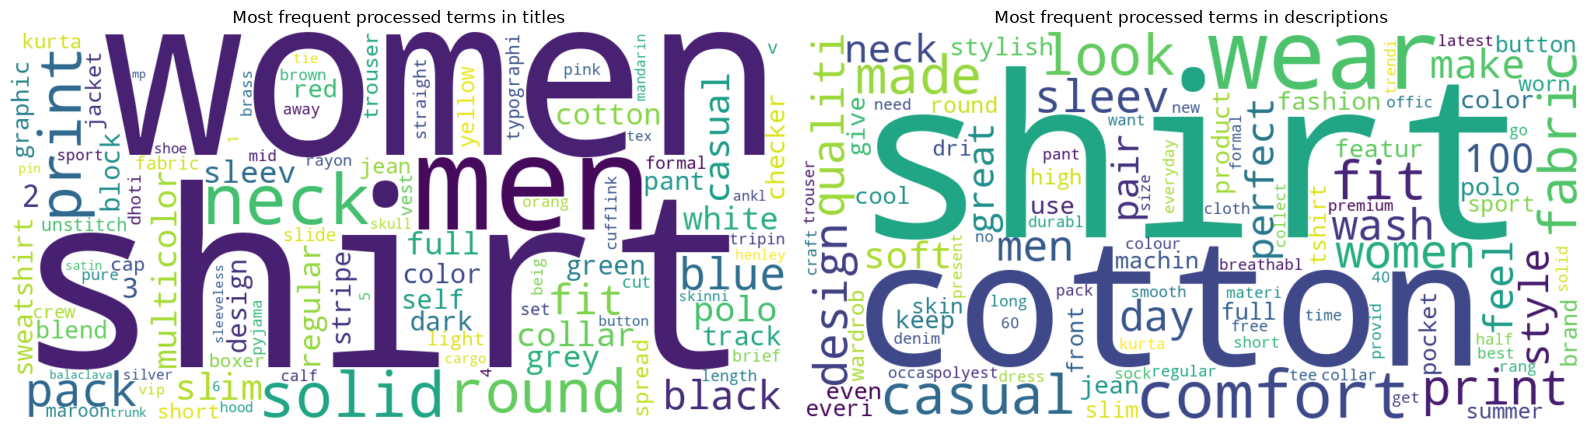

In [30]:
# function to be reused for both term clouds and entity clouds:
def plot_wordcloud(ax, frequencies, title, colormap="viridis"):
    ax.set_title(title)
    ax.axis("off")

    if not frequencies:
        ax.text(
            0.5, 0.5,
            "No terms available",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        return

    cloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        max_words=100,
        random_state=42,
        colormap=colormap
    ).generate_from_frequencies(frequencies)

    ax.imshow(cloud, interpolation="bilinear")


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, field in zip(axes, ["title", "description"]):
    plot_wordcloud(
        ax,
        term_counts[field],
        f"Most frequent processed terms in {field}s"
    )

plt.tight_layout()
plt.show()

### Name Entity Recognition

As suggested in the project guidelines, we perform a brief Named Entity Recognition exploration. We have decided to apply it to original descriptions in order to preserve the original wording before tokenization and stemming.

In [31]:
import spacy
from tqdm.auto import tqdm

# Download NER model if not already dowloaded
!python -m spacy download en_core_web_sm

  Using cached https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl (12.8 MB)

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [32]:
# load the model components needed for NER.
nlp = spacy.load(
    "en_core_web_sm",
    enable=["tok2vec", "ner"]
)

# Preserve original wording and capitalization.
ner_input = df[["pid", "description"]].copy()

# Earlier missing-value statistics are already available.
# Here, simply select usable descriptions for the model.
ner_input = ner_input.loc[
    ner_input["description"].notna()
    & ner_input["description"].str.strip().ne("")
].copy()

# Avoid running the model repeatedly on identical descriptions.
unique_descriptions = ner_input["description"].drop_duplicates()

entity_records = []

for doc in tqdm(
    nlp.pipe(unique_descriptions, batch_size=64),
    total=len(unique_descriptions),
    desc="Processing unique descriptions"
):
    for entity in doc.ents:
        # Normalize whitespace and case for frequency grouping.
        # Preserve the model's original text for inspection.
        normalized_entity = " ".join(entity.text.split()).casefold()

        if normalized_entity:
            entity_records.append({
                "description": doc.text,
                "entity_text": entity.text,
                "entity": normalized_entity,
                "label": entity.label_
            })

description_entities = pd.DataFrame(
    entity_records,
    columns=["description", "entity_text", "entity", "label"]
)

# Restore product-level mentions:
# identical descriptions on different products count for each product.
entities_df = ner_input.merge(
    description_entities,
    on="description",
    how="inner"
)

print(f"Nonblank product descriptions: {len(ner_input):,}")
print(f"Unique descriptions processed: {len(unique_descriptions):,}")
print(f"Entity mentions across products: {len(entities_df):,}")
print(
    "Products with detected entities: "
    f"{entities_df['pid'].nunique():,}"
)

# Inspect predictions alongside their original context.
if not entities_df.empty:
    display(
        entities_df.sample(
            n=min(15, len(entities_df)),
            random_state=42
        )[["entity_text", "label", "description"]]
    )
else:
    print("No entities were detected.")

Processing unique descriptions: 100%|██████████| 5683/5683 [00:28<00:00, 201.23it/s]

Nonblank product descriptions: 16,930
Unique descriptions processed: 5,683
Entity mentions across products: 48,142
Products with detected entities: 14,047


,entity_text,label,description
22384,240 GSM,QUANTITY,Beat the heat this summer with the Scott Men C...
6576,daily,DATE,Brand name : Softy Jeans\n\nColor : Black\n\nS...
42338,daily,DATE,New women Cotton White 3.80 meters dhoti with ...
2705,half,CARDINAL,"shirts,casual shirt ,half sleeve shirt,women p..."
25154,U.S.,GPE,Track pant with contrast zipper pockets. Broad...
46406,60%,PERCENT,EXPERIENCE THE AMAZING COMFORT OF A KEOTI POLO...
30923,Colors (Multicolor) • Material: Premium Cotton,WORK_OF_ART,Socks with Dual layer fibers designed to keep ...
664,6,CARDINAL,Fresh Feet combines the best of organically gr...
36847,F VECTOR TEE,PRODUCT,CL F VECTOR TEE
39820,Half & Full Sleeve,ORG,Free Authority Presents this Graphic Printed T...


In [33]:
entity_counts = (
    entities_df.groupby(["label", "entity"])
    .size()
    .reset_index(name="mentions")
    .sort_values(
        ["label", "mentions", "entity"],
        ascending=[True, False, True]
    )
)

entity_summary = (
    entity_counts.groupby("label")["mentions"]
    .sum()
    .to_frame()
    .sort_values("mentions", ascending=False)
)

top_examples = (
    entity_counts.groupby("label")
    .head(3)
    .assign(
        example=lambda table:
            table["entity"] + " (" + table["mentions"].astype(str) + ")"
    )
    .groupby("label")["example"]
    .agg("; ".join)
)

entity_summary["examples (mention counts)"] = top_examples

with pd.option_context("display.max_colwidth", None):
    display(entity_summary)

,mentions,examples (mention counts)
label,,
ORG,14333,keoti (431); printed (382); the amazing comfort of a shoefly polo t-shirts (247)
PERSON,9681,arbour (431); casual wear (418); track pant (400)
PERCENT,5483,100% (3005); 60% (1095); 40% (1048)
DATE,5425,daily (543); weekend (541); some days (529)
GPE,4157,cotton (918); kurta (911); india (624)
CARDINAL,3548,half (732); one (423); 2 (354)
NORP,1792,jeans (582); joggers (237); indian (203)
WORK_OF_ART,1715,shirt for women women (192); t shirt for men women (185); comfort fit (93)
PRODUCT,516,round (130); everland (48); t-shirts (46)


If we observe the most frequent predictions, we can see a lot of labeling problems. For example, “casual wear” and “track pant” are classified as people, “cotton” and “kurta” as countries or citiesm and “jeans” and “joggers” as nationalities or religious/political groups.

Some other predictions are plausible, including percentages, measurements, and “India” as a geographical entity. However, these cases are not enough to evaluate this simple NER as a reliable tool. We might explore different tools, but for now we believe we will not use it to enrich the search index.